# Example of the aitlas toolbox in the context of semantic segmentation

## Import the required packages

In [ ]:
import sys
sys.path.insert(0, "..")  # makes the datasets package of this repository importable
from datasets import EORSSDDataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

Total number of patches: 1400


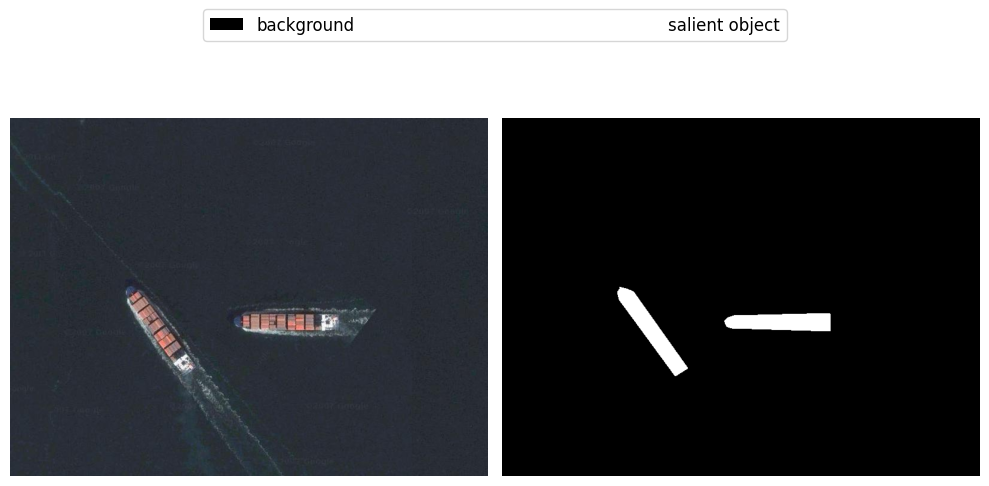

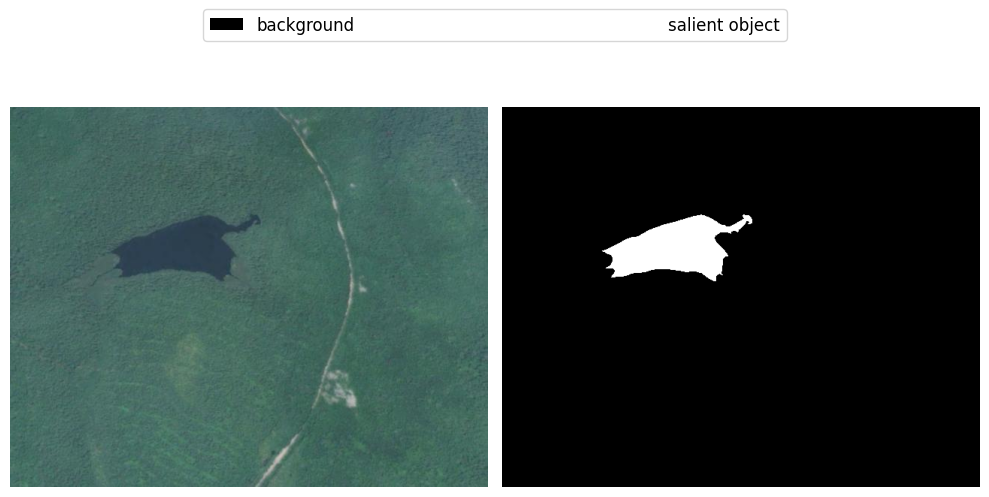

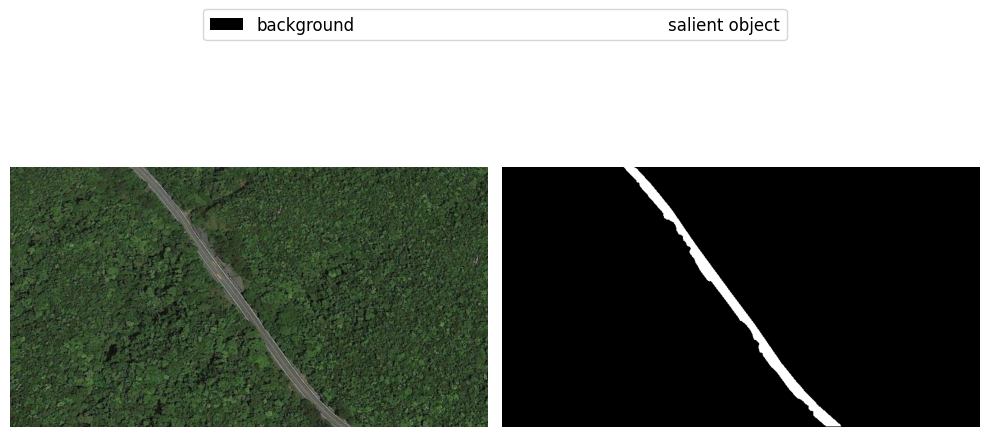

In [ ]:
dataset_config = {
    "data_dir": "./data/eorssd/train"
}
dataset = EORSSDDataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")
dataset.show_image(10);
dataset.show_image(50);
dataset.show_image(500);

In [7]:
dataset.data_distribution_table()

,Number of pixels
background,359689440.0
salient object,19051581.0


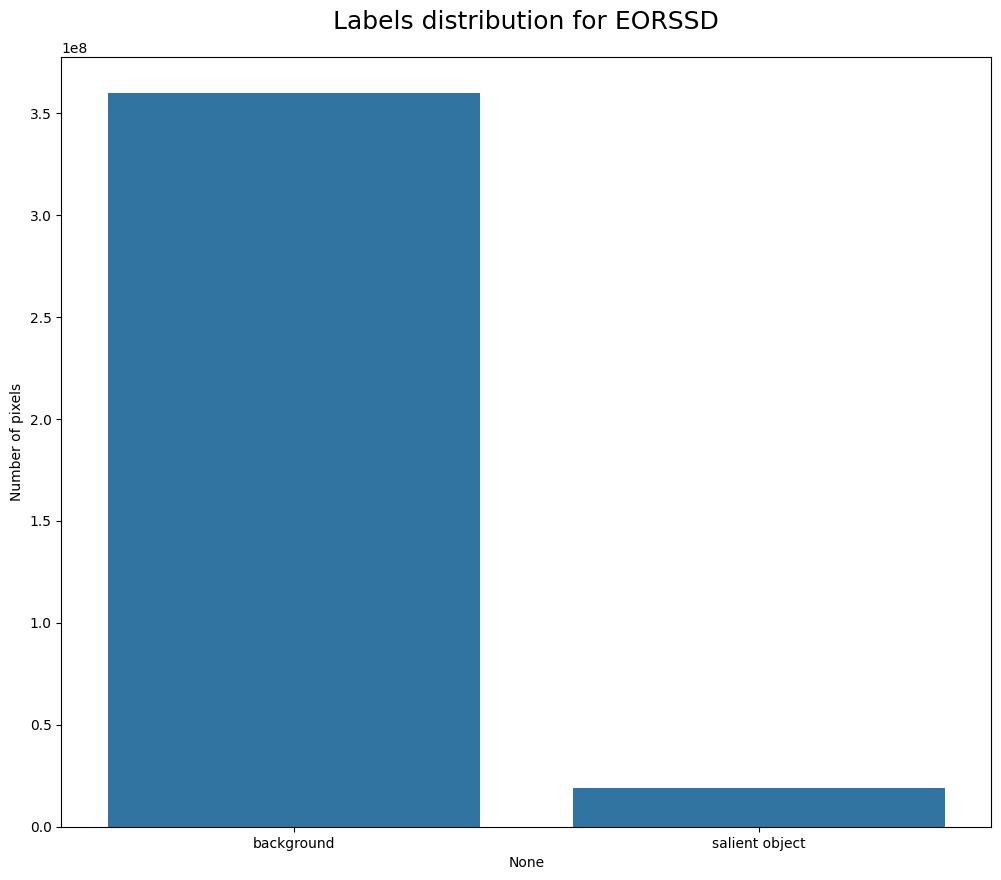

In [8]:
dataset.data_distribution_barchart();

## Load training data

In [ ]:
train_dataset_config = {
    "batch_size": 10,
    "shuffle": True,
    "num_workers": 4,
    "data_dir": "./data/eorssd/train",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}
train_dataset = EORSSDDataset(train_dataset_config)
len(train_dataset)

1400

## Create the model

In [ ]:
epochs = 10
model_directory = "./data/experiments/eorssd"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training

In [11]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
);

2025-11-13 10:07:44,661 INFO Starting training.
training: 100%|██████████| 140/140 [04:51<00:00,  2.08s/it]
2025-11-13 10:12:36,312 INFO epoch: 1, time: 292, loss:  0.31055
testing on train set: 100%|██████████| 140/140 [05:08<00:00,  2.21s/it]
2025-11-13 10:17:46,748 INFO IOU:0.8087443686254181, IOU mean:0.581856235875163, IOU per Class:[0.96297894 0.20073354]
training: 100%|██████████| 140/140 [04:45<00:00,  2.04s/it]
2025-11-13 10:22:31,966 INFO epoch: 2, time: 285, loss:  0.18197
testing on train set: 100%|██████████| 140/140 [04:38<00:00,  1.99s/it]
2025-11-13 10:27:10,090 INFO IOU:0.9441692190603714, IOU mean:0.7738260820478196, IOU per Class:[0.97557458 0.57207759]
training: 100%|██████████| 140/140 [04:49<00:00,  2.07s/it]
2025-11-13 10:31:59,458 INFO epoch: 3, time: 289, loss:  0.10928
testing on train set: 100%|██████████| 140/140 [04:37<00:00,  1.98s/it]
2025-11-13 10:36:37,070 INFO IOU:0.9695653891460662, IOU mean:0.8626197624636377, IOU per Class:[0.98420787 0.74103165]
tr

## Evaluate the model

In [ ]:
test_dataset_config = {
    "batch_size": 8,
    "shuffle": False,
    "num_workers": 4,
    "data_dir": "./data/eorssd/test",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"], 
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"] 
}

test_dataset = EORSSDDataset(test_dataset_config)
print(len(test_dataset))

model = DeepLabV3(model_config)
model.prepare()
model.running_metrics.reset()
model_path = "./data/experiments/eorssd/checkpoint.pth.tar"
model.evaluate(dataset=test_dataset, model_path=model_path)
model.running_metrics.get_scores(model.metrics)

600


2025-11-13 12:07:34,721 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/eorssd/checkpoint.pth.tar
2025-11-13 12:07:35,151 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/eorssd/checkpoint.pth.tar at epoch 11
testing on test set: 100%|██████████| 75/75 [01:58<00:00,  1.58s/it]


[{'IOU': 0.9710831449386093,
  'IOU mean': 0.8537595162158031,
  'IOU per Class': array([0.98352699, 0.72399204])}]

## Predictions

2025-11-13 12:09:33,335 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/eorssd/checkpoint.pth.tar
2025-11-13 12:09:33,727 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/eorssd/checkpoint.pth.tar at epoch 11


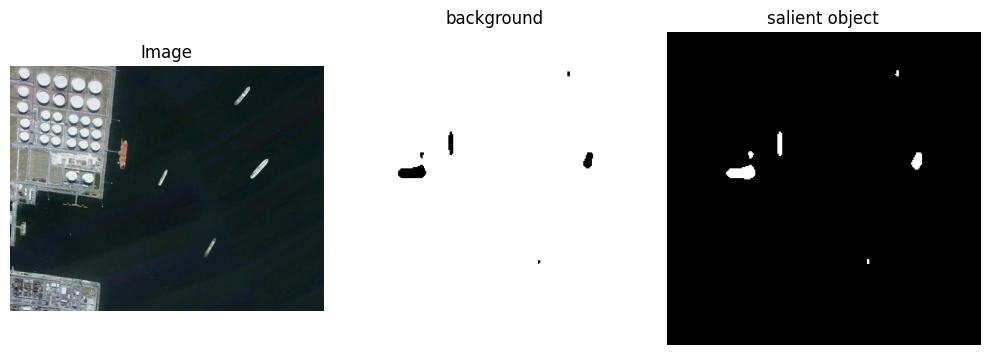

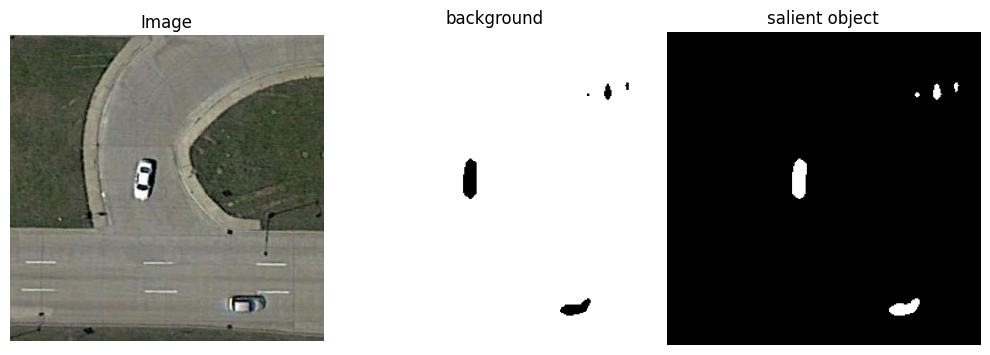

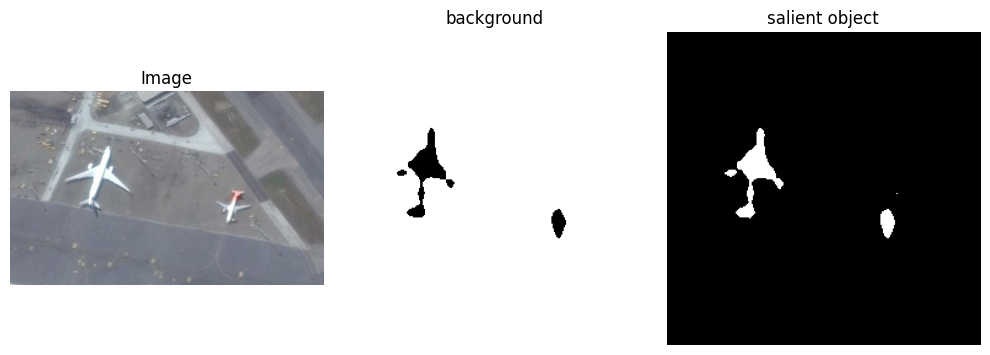

In [ ]:
model_path = "./data/experiments/eorssd/checkpoint.pth.tar"
labels = ["background","salient object"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/eorssd/test/images/0006.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/eorssd/test/images/0658.jpg')
fig = model.predict_masks(image, labels, transform)

image = image_loader('./data/eorssd/test/images/1513.jpg')
fig = model.predict_masks(image, labels, transform)